Fase 1.

- [ ] Configuar
 gymnasium con acrobot-v1.

In [ ]:
#!pip install gymnasium
#pip install matplotlib
#!pip install "gymnasium[classic-control]"
#!pip install imageio
#!pip install IPython

In [3]:


import gymnasium as gym

import matplotlib.pyplot as plt

#import gymnasium[classic-control] as gym

#import imageio

import IPython 

import numpy as np


In [4]:

env= gym.make("Acrobot-v1", render_mode="rgb_array")
env.reset(seed=45,options={"low":-0.1,"high":0.1}) #las opciones son los límites que se usan para determinar los ángulos al arrancar


(array([0.99989307, 0.01462561, 0.9999838 , 0.0056982 , 0.05273005,
        0.06233855], dtype=float32),
 {})

In [18]:

print("Límite inferior y límite superior de cada una de las 6 componentes")
print(env.observation_space)
print("acciones")
print(env.action_space)
env.action_space.n
type(env.observation_space.shape.prod())

Límite inferior y límite superior de cada una de las 6 componentes
Box([ -1.        -1.        -1.        -1.       -12.566371 -28.274334], [ 1.        1.        1.        1.       12.566371 28.274334], (6,), float32)
acciones
Discrete(3)


AttributeError: 'tuple' object has no attribute 'prod'

In [18]:
print(env.reset(seed=45)[1])

{}


Primer objeto: el estado inicial
segundo:

Arranca abajo con un poquito de velocidad.

La recompensa por paso es -1. \
La recompensa al llegar al estado final es 0. \
El límite de recompensa es -100. (¿Por qué tiene límite la recompensa si se pueden tomar hasta 200 pasos?)

Agente aleatorio: Loop reset -> step -> ... hasta que el episodio termine, usando env.action_space.sample()

# Ver un paso al azar

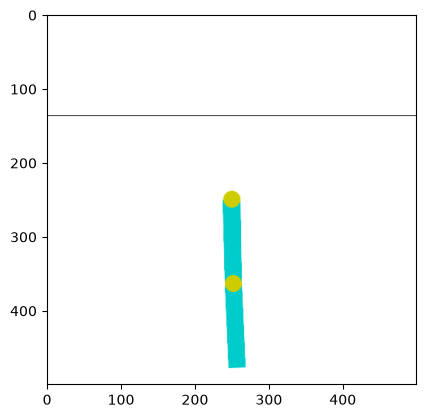

In [ ]:
env= gym.make("Acrobot-v1", render_mode="rgb_array")



# observación inicial
observation,info= env.reset(seed=45,options={"low":-0.1,"high":0.1}) #las opciones son los límites que se usan para determinar los ángulos al arrancar

#tomar una accion al azar
action= env.action_space.sample()

# tomamos un paso
# recibimos la observación siguiente, reward y si el episodio terminó o se truncó
observation, reward, terminated, truncated,info= env.step(action)


plt.imshow(env.render())

# Aplicar torque a la izquierda

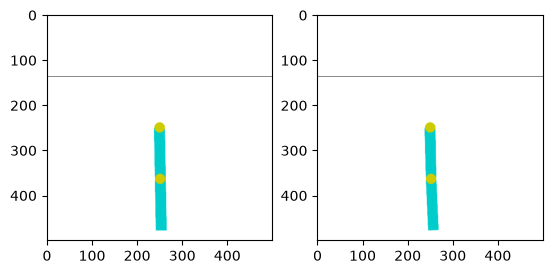

In [54]:




# observación inicial
observation,info= env.reset(seed=45,options={"low":-0.1,"high":0.1}) #las opciones son los límites que se usan para determinar los ángulos al arrancar

frame1=env.render()


# tomamos un paso
# recibimos la observación siguiente, reward y si el episodio terminó o se truncó
observation, reward, terminated, truncated,info= env.step(1)

frame2=env.render()

figura,ejes= plt.subplots(1,2)
ax,ay=ejes

ax.imshow(frame1)
ay.imshow(frame2)

# Agente aleatorio: un episodio

In [ ]:

truncated=False
terminated= False
frames=[]
while not (terminated or truncated):
    # this is where you would insert your policy
    action = env.action_space.sample()

    # step (transition) through the environment with the action
    # receiving the next observation, reward and if the episode has terminated or truncated
    observation, reward, terminated, truncated, info = env.step( action)  
    
    frames.append(env.render())
    #imageio.mimsave sirve para escribir varias imágenes en un archivo
    
env.close()


imageio.mimsave("episodio.gif",frames)

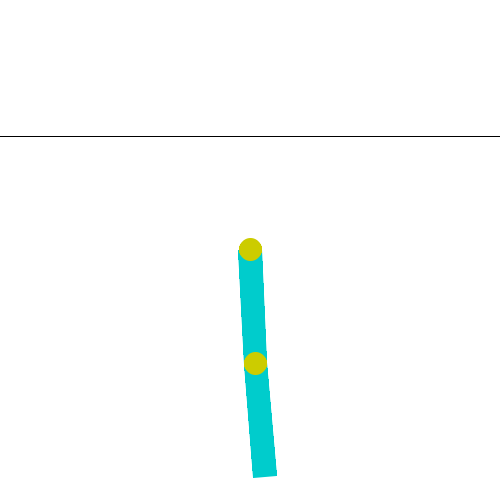

In [76]:
IPython.display.Image(filename="episodio.gif")

Métricas base: Corremos varios episodios  y calculamos la esperanza promedio del retorno.

In [ ]:
def retorno_y_longitud_azar(semilla,Nrep):
    """
    Nrep es la cantidad de episodios que querés que ocurran

    devuelve un diccionario {"retornos","pasos"}
    retornos es una lista con el retorno de cada episodio
    """
    env= gym.make("Acrobot-v1", render_mode="rgb_array")
    observation, info = env.reset(seed=semilla)
    env.action_space.seed(semilla)

    retorno_episodios=[]
    longitud_episodios=[]
    for i in range(Nrep):
        observation, info = env.reset()
        truncated=False
        terminated= False

        retorno_acum=0
        N_pasos=0
        while not (terminated or truncated):
            # this is where you would insert your policy
            action = env.action_space.sample()

            # step (transition) through the environment with the action
            # receiving the next observation, reward and if the episode has terminated or truncated
            observation, reward, terminated, truncated, info = env.step( action)  
            retorno_acum+=reward
            N_pasos+=1


            
        
        retorno_episodios.append(retorno_acum)
        longitud_episodios.append(N_pasos)
    env.close()
    return {"retornos":retorno_episodios, "pasos":longitud_episodios}

In [ ]:
resultado=retorno_y_longitud_azar(42,1000)
retorno_episodios=resultado["retornos"]
longitud_episodios=resultado["longitud_episodios"]

retornos


ValueError: x and y must be the same size

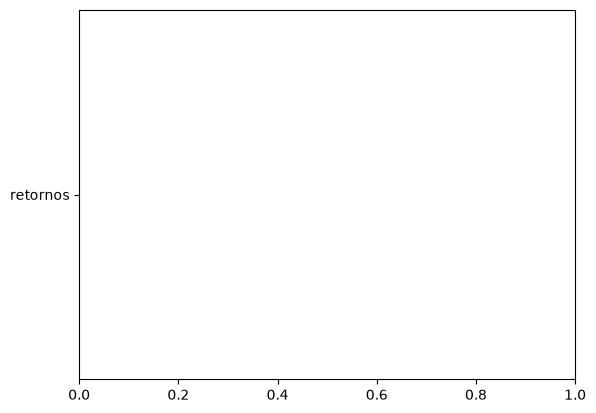

In [143]:
plt.scatter(range(0,1000),retorno_episodios)


(array([983.,   0.,   0.,   0.,   1.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   1.,
          0.,   0.,   0.,   1.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   1.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   1.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          2.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0., 

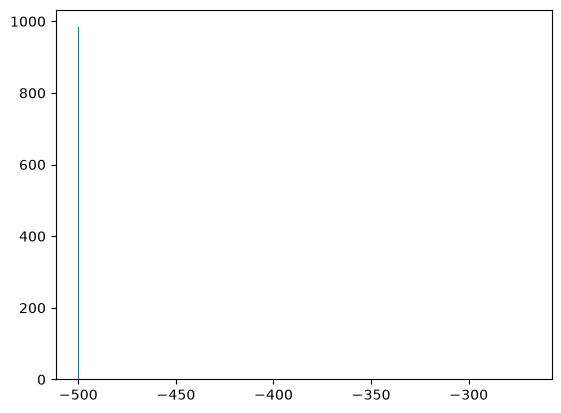

In [135]:
plt.hist(retorno_episodios,bins=500)

(array([  1.,   0.,   1.,   1.,   0.,   4.,   3.,   2.,   1., 987.]),
 array([270., 293., 316., 339., 362., 385., 408., 431., 454., 477., 500.]),
 <BarContainer object of 10 artists>)

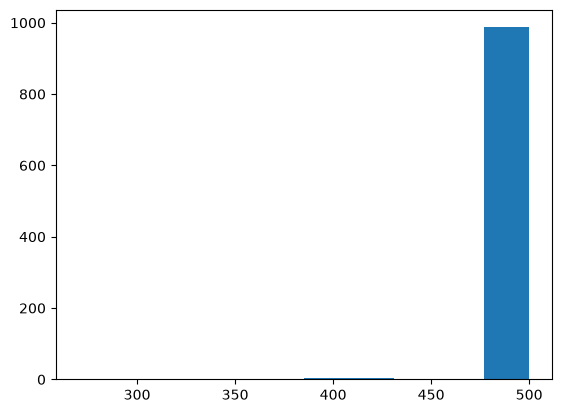

In [136]:
plt.hist(longitud_episodios)

Con el agente aleatorio, la mayoría de las veces el episodio termina después de 500 pasos con un retorno de -500

In [137]:
print(np.mean(retorno_episodios))
print(np.std(retorno_episodios))

-498.613
13.087292729972845


In [138]:
print(np.mean(longitud_episodios))
print(np.std(longitud_episodios))


498.63
12.983339323918173
